[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_oos_trend/BA_L1_oos_trend.ipynb)

# BA_L1_oos_trend: Out-of-Sample Check of the Trend after One Year

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

The log-linear trend of Bitcoin market value, estimated on monthly means to October 2025, is extended from November 2025 to October 2026 with a naive 95% band and compared with the market value reconstructed from EODHD daily closes to 23 October 2026 and the protocol supply rule.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['statsmodels']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [5]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

1. **Trend.** $\ln M_t = a + g\,t + u_t$ on monthly means of Bitcoin market value, November 2014 to October 2025
   (ETH Chronicles data, the 11 days of recording error removed), $t$ in years.
2. **Forecast.** The fitted line is extended month by month from November 2025 to October 2026. A naive 95% band
   adds $\pm 1.96\,\hat s$ in logs, where $\hat s$ is the residual standard deviation, as if the residuals were
   independent and identically distributed (iid).
3. **Realised value.** EODHD daily close times the circulating supply, averaged by month; prices run to
   23 October 2026, so the October 2026 mean covers 1–23 October. Supply follows the protocol rule at the block rate
   observed since 3 January 2009: the circulating supply of 24 October 2026, 20 102 728 BTC, implies the block height
   $h = 840\,000 + (20\,102\,728 - 19\,687\,500)/3.125$, and $h$ divided by the days since genesis gives the blocks
   per day.

The first-order autocorrelation of the trend residuals (the AR(1) coefficient) measures how persistent the deviations
from the trend are; a value close to 1 means that the iid band is far too narrow beyond a few months.

**How to read the chart.** Orange: the estimation sample; dashed blue: the fitted trend; solid blue and shaded: the
forecast and its naive band; red: the reconstructed market value.

In [6]:
import statsmodels.api as sm

tx, mc = load_onchain('transaction'), load_onchain('Mktcap')
mc.loc['2023-08-27':'2023-09-06', 'BTC'] = np.nan          # recording error
series = {'transactions per day': tx['BTC'], 'market value (USD million)': mc['BTC'] / 1e6}
trend = {}
for lab, s in series.items():
    mth = s.resample('ME').mean().dropna()                 # monthly means
    t = np.arange(len(mth)) / 12                            # time in years
    trend[lab] = (mth, sm.OLS(np.log(mth.values), sm.add_constant(t)).fit(cov_type='HAC', cov_kwds={'maxlags': 12}))

mth, fit = trend['market value (USD million)']
mth = mth * 1e6                                         # back to USD
t = np.arange(len(mth)) / 12
sres = np.std(fit.resid, ddof=2)                        # residual standard deviation, in logs

In [7]:
actual_supply = 20_102_728                              # circulating BTC on 24 October 2026
height_now = 840_000 + (actual_supply - 19_687_500) / 3.125
bpd = height_now / (pd.Timestamp('2026-10-24') - pd.Timestamp('2009-01-03')).days
days = pd.date_range('2009-01-03', '2030-12-31', freq='D')
S_real = pd.Series(np.minimum(np.cumsum(50 * 0.5 ** np.floor(np.arange(len(days)) * bpd / 210_000) * bpd), 21e6), index=days)
print(f'Implied block height: {height_now:,.0f}; blocks per day since 3 January 2009: {bpd:.2f}')

p = daily('BTC-USD.CC', '2026-10-23')
real = (p * S_real.reindex(p.index)).resample('ME').mean()
fut = pd.date_range('2025-11-30', '2026-10-31', freq='ME')
tf = t[-1] + np.arange(1, len(fut) + 1) / 12
pred = np.exp(fit.params[0] + fit.params[1] * tf) * 1e6
lo, hi = pred * np.exp(-1.96 * sres), pred * np.exp(1.96 * sres)
oos = pd.DataFrame({'trend forecast (USD bn)': pred / 1e9, 'naive 95% band, low (USD bn)': lo / 1e9,
                    'naive 95% band, high (USD bn)': hi / 1e9, 'reconstructed (USD bn)': real.reindex(fut).values / 1e9},
                   index=fut.strftime('%b %Y'))
oos['reconstructed / forecast'] = oos['reconstructed (USD bn)'] / oos['trend forecast (USD bn)']

Implied block height: 972,873; blocks per day since 3 January 2009: 149.60


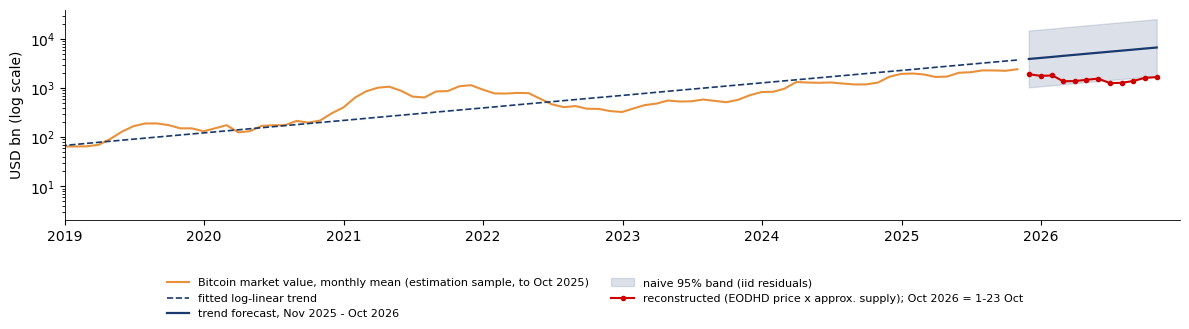

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.3))
ax.plot(mth.index, mth / 1e9, color=BTC, label='Bitcoin market value, monthly mean (estimation sample, to Oct 2025)')
ax.plot(mth.index, np.exp(fit.fittedvalues) * 1e6 / 1e9, color=BLUE, ls='--', lw=1.2, label='fitted log-linear trend')
ax.plot(fut, pred / 1e9, color=BLUE, lw=1.6, label='trend forecast, Nov 2025 - Oct 2026')
ax.fill_between(fut, lo / 1e9, hi / 1e9, color=BLUE, alpha=0.15, label='naive 95% band (iid residuals)')
ax.plot(fut, oos['reconstructed (USD bn)'].values, color=RED, marker='o', ms=3,
        label='reconstructed (EODHD price x approx. supply); Oct 2026 = 1-23 Oct')
ax.set_yscale('log'); ax.set_ylabel('USD bn (log scale)'); ax.set_xlim(pd.Timestamp('2019-01-01'), pd.Timestamp('2026-12-31'))
slide_legend(fig, 0.2, ncol=2)
save_fig(fig, 'ba_oos_trend')

The table of the slide (Bitcoin market value, USD bn) and the persistence of the residuals.

In [9]:
print(f'Trend growth: {100 * (np.exp(fit.params[1]) - 1):.1f}% a year; residual standard deviation (logs): {sres:.3f}')
print(oos.round(2).to_string())
print(f'\nAR(1) coefficient of the trend residuals: {sm.tsa.acf(fit.resid, nlags=1)[1]:.2f}')

Trend growth: 79.7% a year; residual standard deviation (logs): 0.680
          trend forecast (USD bn)  naive 95% band, low (USD bn)  naive 95% band, high (USD bn)  reconstructed (USD bn)  reconstructed / forecast
Nov 2025                  3918.38                       1033.94                       14849.75                 1920.22                      0.49
Dec 2025                  4114.56                       1085.70                       15593.24                 1775.00                      0.43
Jan 2026                  4320.57                       1140.06                       16373.95                 1807.00                      0.42
Feb 2026                  4536.88                       1197.14                       17193.74                 1375.67                      0.30
Mar 2026                  4764.03                       1257.08                       18054.58                 1389.74                      0.29
Apr 2026                  5002.55                       1320